In [1]:
# conda env 'vis2'

import netCDF4 as nc
import xarray as xr
import at3d
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

In [2]:
wavelength = 0.67
wavelength_0 = 0.55

In [3]:
obs_small_file = '../intermediate_data/MISR_OBS_CAMP2Ex_RF17_Pris2.nc'
obs_small = xr.load_dataset(obs_small_file)
obs_file = '../intermediate_data/MISR_OBS_CAMP2Ex_RF17.nc'
obs = xr.load_dataset(obs_file)

aerosol_file = '../../data/MISR/MISR_AM1_AS_AEROSOL_P117_O105254_F13_0023.nc'

dataset = nc.Dataset(aerosol_file,'r')
products = xr.open_dataset(xr.backends.NetCDF4DataStore(dataset['/4.4_KM_PRODUCTS/']))
aux = xr.open_dataset(xr.backends.NetCDF4DataStore(dataset['/4.4_KM_PRODUCTS/AUXILIARY/']))
merged = xr.merge([products, aux])
aerosol_ds = merged.sel(X_Dim=slice(1.774e7,1.816e7), Y_Dim=slice(-0.6e6, 0.6e6)).copy(deep=True)
aerosol_ds['Aerosol_Optical_Depth_Relative_Uncertainty'] = 100*(aerosol_ds.Aerosol_Optical_Depth_Uncertainty / aerosol_ds.Aerosol_Optical_Depth)

(18.0, 19.7)

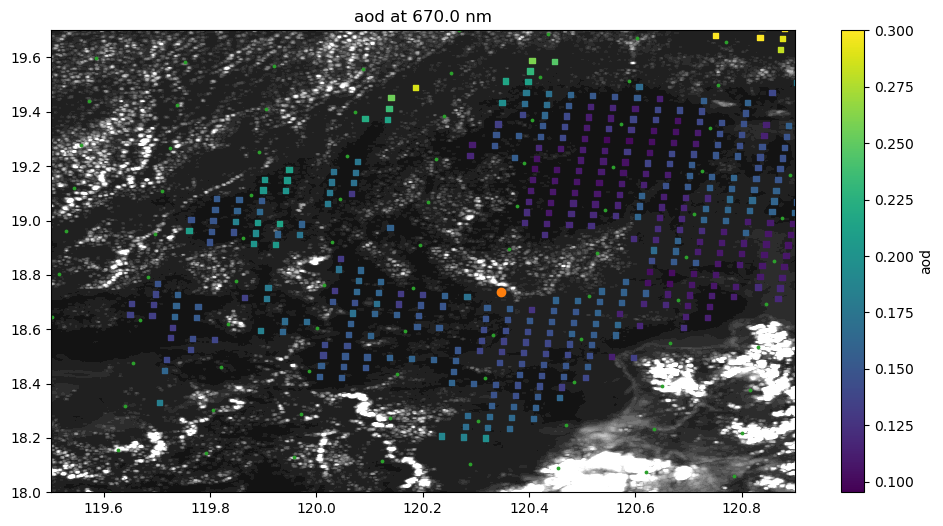

In [4]:
f, ax = plt.subplots(1, 1, figsize=(12,6))
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.3, cmap='gray', levels=100)
lon = aerosol_ds.Longitude.data
lat = aerosol_ds.Latitude.data
aod = aerosol_ds.Aerosol_Optical_Depth.data * (wavelength / wavelength_0) ** aerosol_ds.Angstrom_Exponent_550_860nm.data
c = ax.scatter(np.ravel(lon), np.ravel(lat), c=aod, s=14, alpha=1.0, marker='s', vmin=None, vmax=0.3)
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:green')
ax.scatter(obs_small.center_lon.data, obs_small.center_lat.data, c='tab:orange')
plt.colorbar(c, ax=ax, label='aod')
ax.set_title('aod at {} nm'.format(wavelength*1e3))
# ax.set_xlim([118, 123])
# ax.set_ylim([17.4, 21.5])
ax.set_xlim([119.5, 120.9])
ax.set_ylim([18.0, 19.7])

(17.4, 21.5)

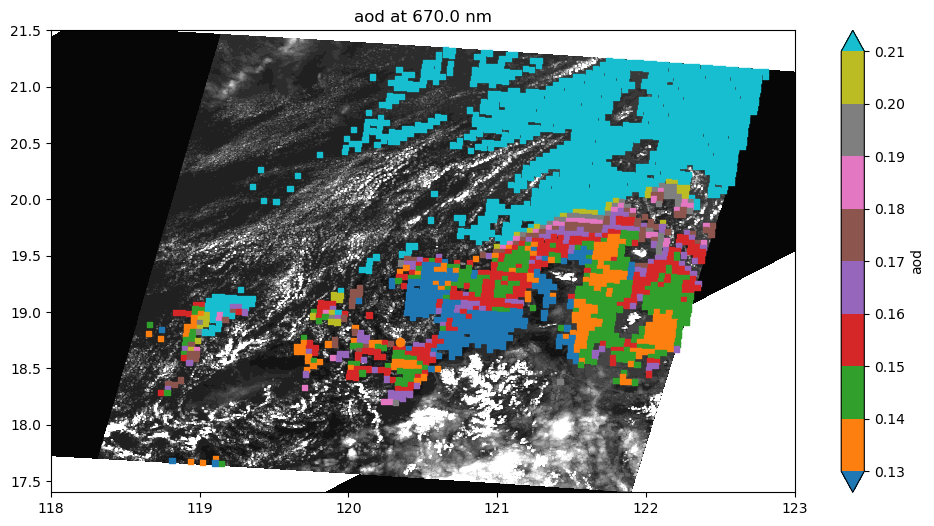

In [5]:
# Define the boundaries and colormap
boundaries = [0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.20, 0.21]  # Extend beyond the min/max values
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']  # Colors for below min, within range, and above max

cmap = mcolors.LinearSegmentedColormap.from_list('custom_cmap', colors)
norm = mcolors.BoundaryNorm(boundaries, cmap.N, extend='both')

f, ax = plt.subplots(1, 1, figsize=(12,6))
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.3, cmap='gray', levels=100)
lon = aerosol_ds.Longitude.data
lat = aerosol_ds.Latitude.data
aod = aerosol_ds.Aerosol_Optical_Depth.data * (wavelength / wavelength_0) ** aerosol_ds.Angstrom_Exponent_550_860nm.data
# c = ax.scatter(np.ravel(lon), np.ravel(lat), c=aod, s=14, alpha=1.0, marker='s', vmin=0.15, vmax=0.3)
c = ax.scatter(np.ravel(lon), np.ravel(lat), c=aod, s=14, alpha=1.0, marker='s', cmap=cmap, norm=norm)
# ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:green')
ax.scatter(obs_small.center_lon.data, obs_small.center_lat.data, c='tab:orange')
plt.colorbar(c, ax=ax, label='aod', extend='both')
ax.set_title('aod at {} nm'.format(wavelength*1e3))
ax.set_xlim([118, 123])
ax.set_ylim([17.4, 21.5])
# ax.set_xlim([119.8, 120.3])
# ax.set_ylim([18.5, 19.4])

0.15161322


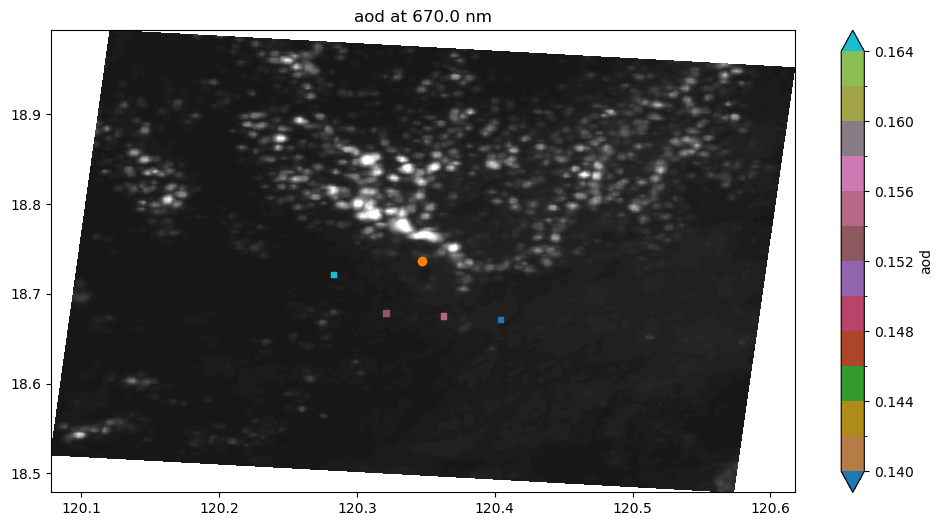

In [17]:
# Define the boundaries and colormap
boundaries = [0.140, 0.142, 0.144, 0.146, 0.148, 0.150, 0.152, 0.154, 0.156, 0.158, 0.160, 0.162, 0.164]  # Extend beyond the min/max values
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']  # Colors for below min, within range, and above max

cmap = mcolors.LinearSegmentedColormap.from_list('custom_cmap', colors)
norm = mcolors.BoundaryNorm(boundaries, cmap.N, extend='both')

f, ax = plt.subplots(1, 1, figsize=(12,6))
ax.contourf(obs_small.lon275.data, obs_small.lat275.data, obs_small.brf.isel(camera=4).data, vmin=0, vmax=0.3, cmap='gray', levels=100)
lon = aerosol_ds.Longitude.data
lat = aerosol_ds.Latitude.data
aod = aerosol_ds.Aerosol_Optical_Depth.data * (wavelength / wavelength_0) ** aerosol_ds.Angstrom_Exponent_550_860nm.data
cond = np.logical_and(np.logical_and(lat>18.5, lat<19.0), np.logical_and(lon>120.1, lon<120.6))
cond = np.logical_and(np.logical_and(lat>18.65, lat<18.8), np.logical_and(lon>120.25, lon<120.42))
# c = ax.scatter(np.ravel(lon[cond]), np.ravel(lat[cond]), c=aod[cond], s=14, alpha=1.0, marker='s', vmin=0.14, vmax=0.19)
c = ax.scatter(np.ravel(lon[cond]), np.ravel(lat[cond]), c=aod[cond], s=14, alpha=1.0, marker='s', cmap=cmap, norm=norm)
# ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:green')
ax.scatter(obs_small.center_lon.data, obs_small.center_lat.data, c='tab:orange')
plt.colorbar(c, ax=ax, label='aod', extend='both')
ax.set_title('aod at {} nm'.format(wavelength*1e3))
# ax.set_xlim([118, 123])
# ax.set_ylim([17.4, 21.5])
# ax.set_xlim([119.8, 120.3])
# ax.set_ylim([18.5, 19.4])
print(np.nanmean(aod[cond]))

(17.4, 21.5)

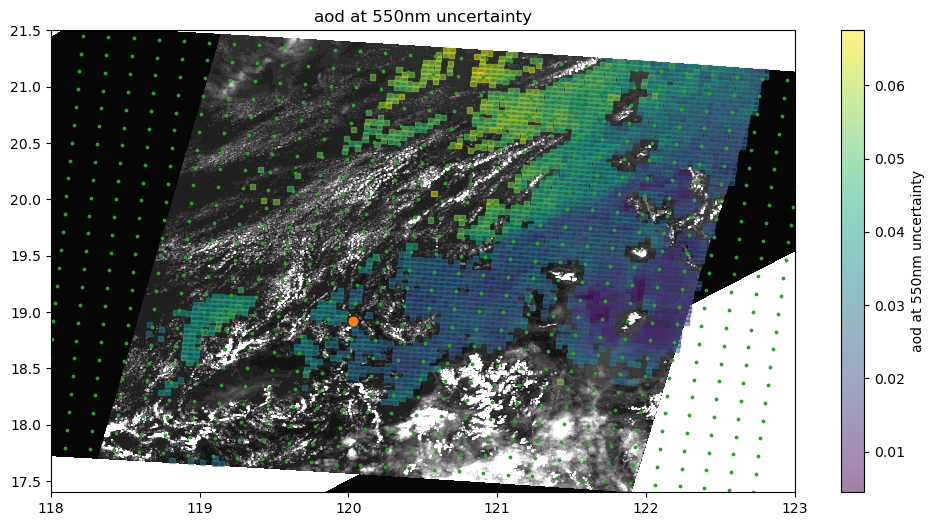

In [16]:
f, ax = plt.subplots(1, 1, figsize=(12,6))
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.3, cmap='gray', levels=100)
lon = aerosol_ds.Longitude.data
lat = aerosol_ds.Latitude.data
aod_u = aerosol_ds.Aerosol_Optical_Depth_Uncertainty.data
c = ax.scatter(np.ravel(lon), np.ravel(lat), c=aod_u, s=14, alpha=0.5, marker='s')
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:green')
ax.scatter(obs_small.center_lon.data, obs_small.center_lat.data, c='tab:orange')
plt.colorbar(c, ax=ax, label='aod at 550nm uncertainty')
ax.set_title('aod at 550nm uncertainty')
ax.set_xlim([118, 123])
ax.set_ylim([17.4, 21.5])

(17.0, 21.5)

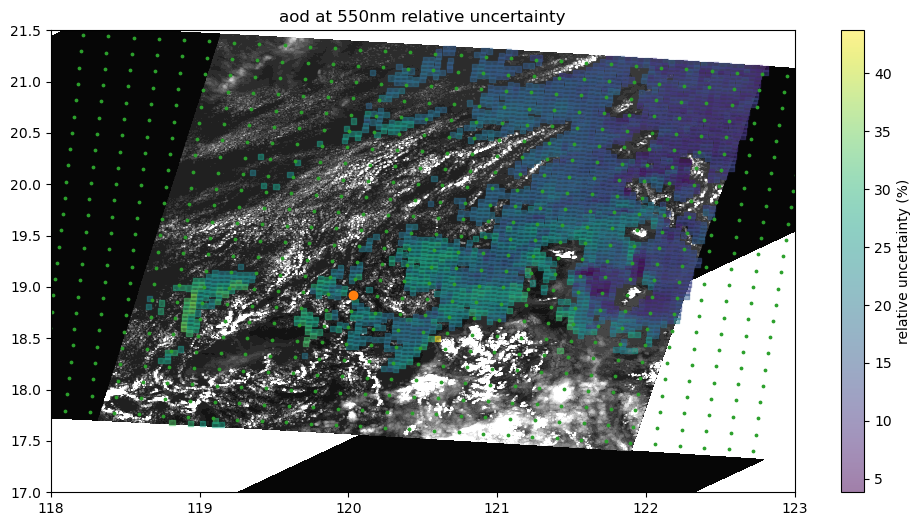

In [17]:
f, ax = plt.subplots(1, 1, figsize=(12,6))
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.3, cmap='gray', levels=100)
lon = aerosol_ds.Longitude.data
lat = aerosol_ds.Latitude.data
aod_ru = aerosol_ds.Aerosol_Optical_Depth_Relative_Uncertainty.data
c = ax.scatter(np.ravel(lon), np.ravel(lat), c=aod_ru, s=14, alpha=0.5, marker='s')
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:green')
ax.scatter(obs_small.center_lon.data, obs_small.center_lat.data, c='tab:orange')
plt.colorbar(c, ax=ax, label='relative uncertainty (%)')
ax.set_title('aod at 550nm relative uncertainty')
ax.set_xlim([118, 123])
ax.set_ylim([17, 21.5])

(17.0, 21.5)

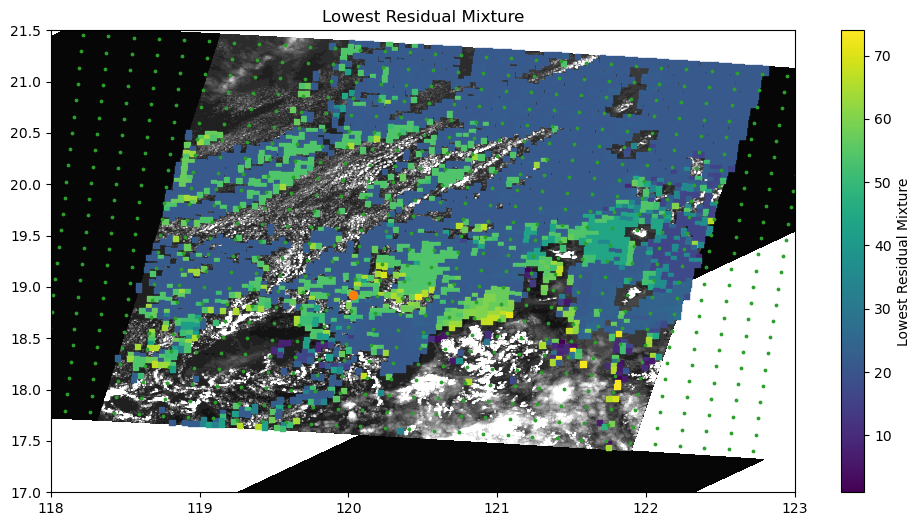

In [18]:
f, ax = plt.subplots(1, 1, figsize=(12,6))
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.3, cmap='gray', levels=100)
lon = aerosol_ds.Longitude.data
lat = aerosol_ds.Latitude.data
lrm = aerosol_ds.Lowest_Residual_Mixture.data
c = ax.scatter(np.ravel(lon), np.ravel(lat), c=lrm, s=14, alpha=1.0, marker='s')
plt.colorbar(c, ax=ax, label='Lowest Residual Mixture')
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:green')
ax.scatter(obs_small.center_lon.data, obs_small.center_lat.data, c='tab:orange')
ax.set_title('Lowest Residual Mixture')
ax.set_xlim([118, 123])
ax.set_ylim([17, 21.5])

Text(0.5, 1.0, 'Lowest Residual Mixture')

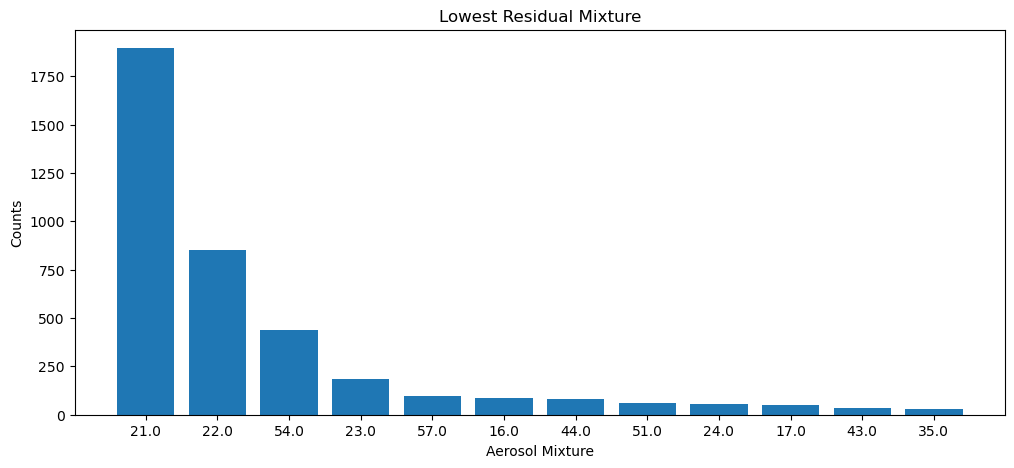

In [19]:
n_mixtures = 12
hist, bin_edges = np.histogram(aerosol_ds.Lowest_Residual_Mixture.data, bins=74, range=(0.5, 74.5))
midpoints = (bin_edges[:-1] + bin_edges[1:])/2
sorted_hist = np.sort(hist)
sorted_hist = sorted_hist[::-1]
sorted_midpoints = midpoints[np.argsort(hist)]
sorted_midpoints = sorted_midpoints[::-1]
f, ax = plt.subplots(1, 1, figsize=(12,5))
ax.bar(sorted_midpoints.astype('str')[:n_mixtures], sorted_hist[:n_mixtures])
ax.set_xlabel('Aerosol Mixture')
ax.set_ylabel('Counts')
ax.set_title('Lowest Residual Mixture')

(17.4, 21.5)

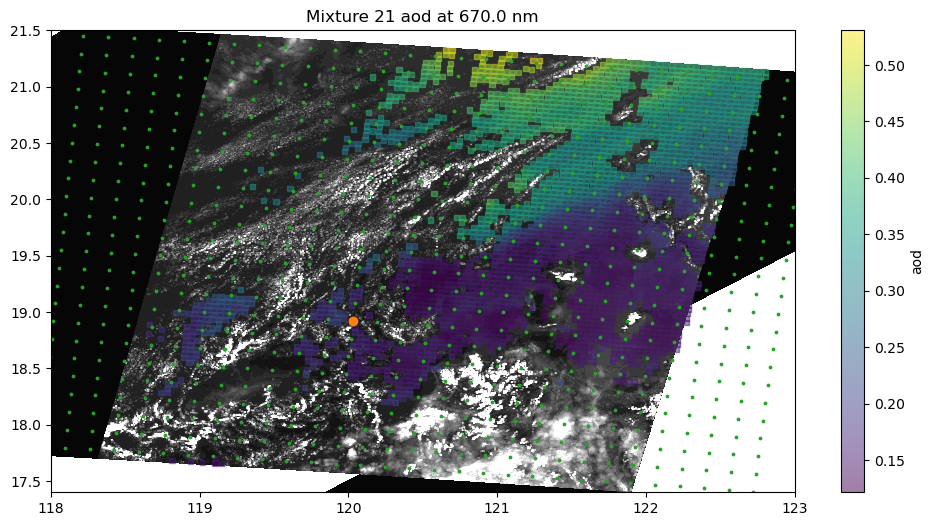

In [20]:
mixture = 21
f, ax = plt.subplots(1, 1, figsize=(12,6))
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.3, cmap='gray', levels=100)
lon = aerosol_ds.Longitude.data
lat = aerosol_ds.Latitude.data
aod_21 = aerosol_ds.sel(Mixture_Dim=mixture).Aerosol_Optical_Depth_Per_Mixture.data  * (wavelength / wavelength_0) ** aerosol_ds.Angstrom_Exponent_550_860nm.data
c = ax.scatter(np.ravel(lon), np.ravel(lat), c=aod_21, s=14, alpha=0.5, marker='s')
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:green')
ax.scatter(obs_small.center_lon.data, obs_small.center_lat.data, c='tab:orange')
plt.colorbar(c, ax=ax, label='aod')
ax.set_title('Mixture {} aod at {} nm'.format(mixture, wavelength*1e3))
ax.set_xlim([118, 123])
ax.set_ylim([17.4, 21.5])